<a href="https://colab.research.google.com/github/kafilatmusa1-droid/rl-sarsa-qlearning/blob/main/RL_SARSA_QLearning_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1 - Install packages (Colab already has most of them)
!pip -q install gymnasium scipy pandas matplotlib

In [2]:
# CELL 2 - Settings, Google Drive and folders
import os, sys, json, platform, warnings
from pathlib import Path
from itertools import product

QUICK_TEST = False          # <-- set to False for the full study

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/RL_SARSA_QLearning_Project')
except ImportError:          # not running in Colab (e.g. on your own computer)
    PROJECT_DIR = Path('./RL_SARSA_QLearning_Project')

OUTPUT_DIR = PROJECT_DIR / ('outputs_quicktest' if QUICK_TEST else 'outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np, pandas as pd, scipy, matplotlib
import matplotlib.pyplot as plt
import gymnasium as gym
from scipy import stats

# Two environments. Each has its own start, goal, hazard rule and success threshold.
ENVS = {
    'CliffWalking': {'env_id': 'CliffWalking-v1', 'kwargs': {}, 'n_states': 48,
                     'start': 36, 'goal': 47, 'threshold': -20.0},
    'FrozenLake':   {'env_id': 'FrozenLake-v1', 'kwargs': {'map_name': '4x4', 'is_slippery': True},
                     'n_states': 16, 'start': 0, 'goal': 15, 'threshold': 0.5},
}
ENV_NAMES = list(ENVS)
ALGORITHMS = ['SARSA', 'Q-learning']
DECAY_FRACTIONS = [0.25, 0.50, 0.75]
GAMMA = 0.99
TRAIN_STEPS = 50_000
TUNE_STEPS = 15_000
ALPHA_CANDIDATES = [0.1, 0.3, 0.5]
TUNING_SEEDS = [100, 101, 102]
FINAL_SEEDS = list(range(42, 52))          # 10 seeds
EVAL_INTERVAL = 2_500
CHECKPOINT_EPISODES = 20
FINAL_EVAL_EPISODES = 100
EVAL_MAX_STEPS = 500
EPS_START, EPS_MIN = 1.0, 0.05

if QUICK_TEST:   # tiny settings only to check that the whole pipeline runs
    TRAIN_STEPS, TUNE_STEPS, EVAL_INTERVAL = 4_000, 2_000, 1_000
    FINAL_SEEDS = list(range(42, 45))
    TUNING_SEEDS = [100]
    CHECKPOINT_EPISODES, FINAL_EVAL_EPISODES = 5, 20

trap = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz   # NumPy version fix
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

versions = {'python': sys.version, 'platform': platform.platform(),
            'gymnasium': gym.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
            'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__,
            'environments': {k: v['env_id'] for k, v in ENVS.items()}}
with open(OUTPUT_DIR / 'software_versions.json', 'w') as f:
    json.dump(versions, f, indent=2)
print(json.dumps(versions, indent=2))
print('Mode:', 'QUICK TEST' if QUICK_TEST else 'FULL STUDY')
print('Outputs will be saved to:', OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "python": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "gymnasium": "1.4.0",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scipy": "1.16.3",
  "matplotlib": "3.10.0",
  "environments": {
    "CliffWalking": "CliffWalking-v1",
    "FrozenLake": "FrozenLake-v1"
  }
}
Mode: FULL STUDY
Outputs will be saved to: /content/drive/MyDrive/RL_SARSA_QLearning_Project/outputs


In [3]:
# CELL 3 - Check both environments and their transition tables
for name, cfg in ENVS.items():
    env = gym.make(cfg['env_id'], **cfg['kwargs'])
    obs, _ = env.reset(seed=123)
    assert isinstance(env.observation_space, gym.spaces.Discrete)
    assert env.observation_space.n == cfg['n_states'], (name, env.observation_space.n)
    assert env.action_space.n == 4
    assert hasattr(env.unwrapped, 'P'), 'Transition table P is missing'
    assert obs == cfg['start'], (name, obs, cfg['start'])
    print(f"{name}: id={cfg['env_id']}, states={cfg['n_states']}, start={obs}, "
          f"transition table covers {len(env.unwrapped.P)} states")
    env.close()
print('Actions in both environments: 0=left/up, 1=down/right, 2=right/down, 3=up/left (see the Word guide).')
print('Environment checks passed.')

CliffWalking: id=CliffWalking-v1, states=48, start=36, transition table covers 48 states
FrozenLake: id=FrozenLake-v1, states=16, start=0, transition table covers 16 states
Actions in both environments: 0=left/up, 1=down/right, 2=right/down, 3=up/left (see the Word guide).
Environment checks passed.


In [4]:
# CELL 4 - Core algorithms: epsilon-greedy, SARSA, Q-learning, evaluation
def make_env(env_name):
    cfg = ENVS[env_name]
    return gym.make(cfg['env_id'], **cfg['kwargs'])

def is_hazard(env_name, reward, terminated):
    """CliffWalking: stepping on the cliff (reward -100). FrozenLake: falling in a hole (terminal, reward 0)."""
    if env_name == 'CliffWalking':
        return bool(np.isclose(float(reward), -100.0))
    return bool(terminated and float(reward) == 0.0)

def epsilon_at_step(step, total_steps, decay_fraction):
    """Linear decay from EPS_START to EPS_MIN over decay_fraction of the budget, then fixed."""
    decay_steps = max(1, int(total_steps * decay_fraction))
    fraction = min(step / decay_steps, 1.0)
    return EPS_START + fraction * (EPS_MIN - EPS_START)

def choose_action(Q, state, epsilon, rng):
    """Epsilon-greedy with random tie-breaking among the best actions."""
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[1]))
    row = Q[state]
    best = np.flatnonzero(np.isclose(row, row.max()))
    return int(rng.choice(best))

def evaluate_policy(env_name, Q, env, episodes=100, seed_base=800_000, max_steps=EVAL_MAX_STEPS):
    """Greedy evaluation (epsilon = 0) on a separate environment with fixed reset seeds."""
    returns, lengths, successes, hazards = [], [], [], 0
    for ep in range(episodes):
        state, _ = env.reset(seed=seed_base + ep)
        total, length, success = 0.0, 0, False
        for _ in range(max_steps):
            action = int(np.argmax(Q[state]))          # greedy: no exploration
            state, reward, terminated, truncated, _ = env.step(action)
            total += float(reward)
            length += 1
            if is_hazard(env_name, reward, terminated):
                hazards += 1
            if terminated:
                success = not is_hazard(env_name, reward, terminated)
                break
            if truncated:
                break
        returns.append(total); lengths.append(length); successes.append(int(success))
    return {'mean_return': float(np.mean(returns)),
            'success_rate': float(np.mean(successes)),
            'mean_episode_length': float(np.mean(lengths)),
            'evaluation_hazard_falls': int(hazards)}

def train_one(env_name, algorithm, alpha, decay_fraction, seed, total_steps,
              eval_interval=None, eval_episodes=20):
    """Train one tabular agent for EXACTLY total_steps environment steps."""
    assert algorithm in ('SARSA', 'Q-learning')
    rng = np.random.default_rng(seed)
    train_env, eval_env = make_env(env_name), make_env(env_name)
    n_states, n_actions = train_env.observation_space.n, train_env.action_space.n
    Q = np.zeros((n_states, n_actions), dtype=np.float64)

    state, _ = train_env.reset(seed=seed)
    action = choose_action(Q, state, EPS_START, rng)
    global_step, hazard_falls = 0, 0
    completed_returns, episode_return = [], 0.0
    eval_rows = []

    while global_step < total_steps:
        next_state, reward, terminated, truncated, _ = train_env.step(action)
        global_step += 1
        episode_return += float(reward)
        if is_hazard(env_name, reward, terminated):
            hazard_falls += 1

        eps_next = epsilon_at_step(global_step, total_steps, decay_fraction)
        if algorithm == 'Q-learning':
            # off-policy: bootstrap from the BEST next action
            target = float(reward) if terminated else float(reward) + GAMMA * np.max(Q[next_state])
            next_action = None
        else:
            # on-policy SARSA: bootstrap from the action the agent will actually take next
            next_action = choose_action(Q, next_state, eps_next, rng)
            target = float(reward) if terminated else float(reward) + GAMMA * Q[next_state, next_action]
        Q[state, action] += alpha * (target - Q[state, action])

        if terminated or truncated:
            completed_returns.append(episode_return)
            episode_return = 0.0
            state, _ = train_env.reset()
            action = choose_action(Q, state, eps_next, rng)
        else:
            state = next_state
            action = next_action if algorithm == 'SARSA' else choose_action(Q, state, eps_next, rng)

        if eval_interval and global_step % eval_interval == 0:
            ev = evaluate_policy(env_name, Q, eval_env, episodes=eval_episodes, seed_base=700_000)
            eval_rows.append({'environment': env_name, 'algorithm': algorithm, 'alpha': alpha,
                              'decay_fraction': decay_fraction, 'seed': seed, 'steps': global_step,
                              'mean_return': ev['mean_return'], 'success_rate': ev['success_rate']})

    assert global_step == total_steps, (global_step, total_steps)
    train_env.close(); eval_env.close()
    result = {'environment': env_name, 'algorithm': algorithm, 'alpha': alpha,
              'decay_fraction': decay_fraction, 'seed': seed,
              'training_steps': global_step, 'training_hazard_falls': hazard_falls,
              'training_hazard_falls_per_1000': hazard_falls / global_step * 1000.0,
              'completed_training_episodes': len(completed_returns)}
    return Q, result, eval_rows
print('Core functions defined.')

Core functions defined.


In [5]:
# CELL 5 - Quick functional test on both environments (should finish in seconds)
for env_name in ENV_NAMES:
    Q_test, res_test, _ = train_one(env_name, 'SARSA', 0.1, 0.5, seed=0, total_steps=2000)
    print(env_name, res_test)
    print('  evaluation:', evaluate_policy(env_name, Q_test, make_env(env_name), episodes=10))

CliffWalking {'environment': 'CliffWalking', 'algorithm': 'SARSA', 'alpha': 0.1, 'decay_fraction': 0.5, 'seed': 0, 'training_steps': 2000, 'training_hazard_falls': 44, 'training_hazard_falls_per_1000': 22.0, 'completed_training_episodes': 5}
  evaluation: {'mean_return': -500.0, 'success_rate': 0.0, 'mean_episode_length': 500.0, 'evaluation_hazard_falls': 0}
FrozenLake {'environment': 'FrozenLake', 'algorithm': 'SARSA', 'alpha': 0.1, 'decay_fraction': 0.5, 'seed': 0, 'training_steps': 2000, 'training_hazard_falls': 207, 'training_hazard_falls_per_1000': 103.5, 'completed_training_episodes': 219}
  evaluation: {'mean_return': 0.0, 'success_rate': 0.0, 'mean_episode_length': 13.6, 'evaluation_hazard_falls': 10}


In [6]:
# CELL 6 - Hyperparameter tuning on SEPARATE tuning seeds (never the final seeds)
tuning_records = []
for env_name, algorithm, decay, alpha, seed in product(ENV_NAMES, ALGORITHMS, DECAY_FRACTIONS,
                                                      ALPHA_CANDIDATES, TUNING_SEEDS):
    Q, res, _ = train_one(env_name, algorithm, alpha, decay, seed, TUNE_STEPS)
    ev = evaluate_policy(env_name, Q, make_env(env_name), episodes=30, seed_base=600_000)
    tuning_records.append({**res, 'tuning_eval_return': ev['mean_return'],
                           'tuning_success_rate': ev['success_rate']})
tuning_df = pd.DataFrame(tuning_records)
tuning_df.to_csv(OUTPUT_DIR / 'tuning_results.csv', index=False)

selected = (tuning_df.groupby(['environment', 'algorithm', 'decay_fraction', 'alpha'])['tuning_eval_return']
            .mean().reset_index()
            .sort_values(['environment', 'algorithm', 'decay_fraction', 'tuning_eval_return'],
                         ascending=[True, True, True, False])
            .drop_duplicates(['environment', 'algorithm', 'decay_fraction']))
alpha_choice = {(r.environment, r.algorithm, float(r.decay_fraction)): float(r.alpha)
                for r in selected.itertuples()}
print(selected.to_string(index=False))
with open(OUTPUT_DIR / 'selected_hyperparameters.json', 'w') as f:
    json.dump({f'{k[0]}_{k[1]}_decay{k[2]}': v for k, v in alpha_choice.items()}, f, indent=2)
print('Selected learning rates saved.')

 environment  algorithm  decay_fraction  alpha  tuning_eval_return
CliffWalking Q-learning            0.25    0.1          -13.000000
CliffWalking Q-learning            0.50    0.1          -13.000000
CliffWalking Q-learning            0.75    0.3          -13.000000
CliffWalking      SARSA            0.25    0.1          -15.000000
CliffWalking      SARSA            0.50    0.1          -15.666667
CliffWalking      SARSA            0.75    0.1          -17.000000
  FrozenLake Q-learning            0.25    0.3            0.744444
  FrozenLake Q-learning            0.50    0.3            0.755556
  FrozenLake Q-learning            0.75    0.3            0.744444
  FrozenLake      SARSA            0.25    0.3            0.677778
  FrozenLake      SARSA            0.50    0.3            0.855556
  FrozenLake      SARSA            0.75    0.3            0.700000
Selected learning rates saved.


In [7]:
# CELL 7 - FINAL experiments: 2 environments x 2 algorithms x 3 decay levels x 10 seeds
final_records, learning_records = [], []
results_path = OUTPUT_DIR / 'final_run_results.csv'
learning_path = OUTPUT_DIR / 'learning_curves.csv'
done = set()
if results_path.exists():            # resume support after a disconnect
    old = pd.read_csv(results_path)
    final_records = old.to_dict('records')
    done = {(r['environment'], r['algorithm'], float(r['decay_fraction']), int(r['seed'])) for r in final_records}
    if learning_path.exists():
        learning_records = pd.read_csv(learning_path).to_dict('records')

for env_name, algorithm, decay, seed in product(ENV_NAMES, ALGORITHMS, DECAY_FRACTIONS, FINAL_SEEDS):
    key = (env_name, algorithm, float(decay), int(seed))
    if key in done:
        print('Skipping completed run:', key)
        continue
    alpha = alpha_choice[(env_name, algorithm, float(decay))]
    Q, res, curve = train_one(env_name, algorithm, alpha, decay, seed, TRAIN_STEPS,
                              eval_interval=EVAL_INTERVAL, eval_episodes=CHECKPOINT_EPISODES)
    fe = evaluate_policy(env_name, Q, make_env(env_name), episodes=FINAL_EVAL_EPISODES, seed_base=900_000)
    final_records.append({**res, 'final_return': fe['mean_return'],
                          'final_success_rate': fe['success_rate'],
                          'final_mean_episode_length': fe['mean_episode_length'],
                          'final_evaluation_hazard_falls': fe['evaluation_hazard_falls']})
    learning_records.extend(curve)
    pd.DataFrame(final_records).to_csv(results_path, index=False)
    pd.DataFrame(learning_records).to_csv(learning_path, index=False)
    np.save(OUTPUT_DIR / f"Q_{env_name}_{algorithm.replace('-', '')}_d{decay}_s{seed}.npy", Q)
    print(f'{env_name:12s} {algorithm:10s} decay={decay:.2f} seed={seed}  return={fe["mean_return"]:.2f}  '
          f'success={fe["success_rate"]:.2f}  hazard falls/1000={res["training_hazard_falls_per_1000"]:.1f}')

final_df = pd.DataFrame(final_records)
expected = len(ENV_NAMES) * len(ALGORITHMS) * len(DECAY_FRACTIONS) * len(FINAL_SEEDS)
print('Total final runs:', len(final_df), f'(expected {expected})')

CliffWalking SARSA      decay=0.25 seed=42  return=-17.00  success=1.00  hazard falls/1000=7.2
CliffWalking SARSA      decay=0.25 seed=43  return=-17.00  success=1.00  hazard falls/1000=7.1
CliffWalking SARSA      decay=0.25 seed=44  return=-17.00  success=1.00  hazard falls/1000=6.1
CliffWalking SARSA      decay=0.25 seed=45  return=-17.00  success=1.00  hazard falls/1000=6.8
CliffWalking SARSA      decay=0.25 seed=46  return=-17.00  success=1.00  hazard falls/1000=6.7
CliffWalking SARSA      decay=0.25 seed=47  return=-17.00  success=1.00  hazard falls/1000=5.8
CliffWalking SARSA      decay=0.25 seed=48  return=-17.00  success=1.00  hazard falls/1000=5.3
CliffWalking SARSA      decay=0.25 seed=49  return=-17.00  success=1.00  hazard falls/1000=5.9
CliffWalking SARSA      decay=0.25 seed=50  return=-17.00  success=1.00  hazard falls/1000=7.1
CliffWalking SARSA      decay=0.25 seed=51  return=-17.00  success=1.00  hazard falls/1000=6.7
CliffWalking SARSA      decay=0.50 seed=42  return

In [8]:
# CELL 8 - Baselines and dynamic-programming references for both environments
def evaluate_random_policy(env_name, episodes=100, seed_base=950_000, max_steps=EVAL_MAX_STEPS):
    env = make_env(env_name)
    rng = np.random.default_rng(seed_base)      # seeded, so it is reproducible
    returns, successes = [], []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed_base + ep)
        total, success = 0.0, False
        for _ in range(max_steps):
            state, reward, terminated, truncated, _ = env.step(int(rng.integers(env.action_space.n)))
            total += float(reward)
            if terminated:
                success = not is_hazard(env_name, reward, terminated)
                break
            if truncated:
                break
        returns.append(total); successes.append(int(success))
    env.close()
    return float(np.mean(returns)), float(np.mean(successes))

def value_iteration(env_name, gamma, theta=1e-12, max_iterations=100_000):
    env = make_env(env_name)
    P = env.unwrapped.P
    n_states, n_actions = env.observation_space.n, env.action_space.n
    V = np.zeros(n_states)
    for it in range(max_iterations):
        delta = 0.0
        for s in range(n_states):
            best = max(sum(p * (r + (0.0 if t else gamma * V[s2])) for p, s2, r, t in P[s][a])
                       for a in range(n_actions))
            delta = max(delta, abs(best - V[s]))
            V[s] = best
        if delta < theta:
            break
    env.close()
    return V, it + 1

def dp_policy_eval(env_name, V, gamma, episodes=200, seed_base=900_000):
    """Greedy policy from V, evaluated with undiscounted returns on the real environment."""
    env = make_env(env_name)
    P = env.unwrapped.P
    n_states, n_actions = env.observation_space.n, env.action_space.n
    Q_star = np.array([[sum(p * (r + (0.0 if t else gamma * V[s2])) for p, s2, r, t in P[s][a])
                        for a in range(n_actions)] for s in range(n_states)])
    returns, successes = [], []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed_base + ep)
        total, success = 0.0, False
        for _ in range(EVAL_MAX_STEPS):
            state, reward, terminated, truncated, _ = env.step(int(np.argmax(Q_star[state])))
            total += float(reward)
            if terminated:
                success = not is_hazard(env_name, reward, terminated)
                break
            if truncated:
                break
        returns.append(total); successes.append(int(success))
    env.close()
    return float(np.mean(returns)), float(np.mean(successes))

ref_rows = []
for env_name in ENV_NAMES:
    start = ENVS[env_name]['start']
    rand_ret, rand_succ = evaluate_random_policy(env_name)
    V_disc, it_disc = value_iteration(env_name, gamma=GAMMA)
    V_undisc, it_undisc = value_iteration(env_name, gamma=1.0)
    # NOTE: this exact value ignores the time limit (for FrozenLake 4x4 it is an upper bound).
    # The simulated greedy policy below respects the time limit: compare learned runs with that row.
    opt_ret, opt_succ = dp_policy_eval(env_name, V_undisc, gamma=1.0)
    row = {'environment': env_name, 'random_mean_return': rand_ret, 'random_success_rate': rand_succ,
           'dp_discounted_value_start': float(V_disc[start]),
           'dp_exact_undiscounted_value_start': float(V_undisc[start]),
           'dp_optimal_undiscounted_return': opt_ret, 'dp_optimal_success_rate': opt_succ}
    ref_rows.append(row)
    print(env_name, {k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items() if k != 'environment'})
pd.DataFrame(ref_rows).to_csv(OUTPUT_DIR / 'baselines_and_dp_reference.csv', index=False)

CliffWalking {'random_mean_return': -4932.9, 'random_success_rate': 0.07, 'dp_discounted_value_start': -12.248, 'dp_exact_undiscounted_value_start': -13.0, 'dp_optimal_undiscounted_return': -13.0, 'dp_optimal_success_rate': 1.0}
FrozenLake {'random_mean_return': 0.01, 'random_success_rate': 0.01, 'dp_discounted_value_start': 0.542, 'dp_exact_undiscounted_value_start': 0.824, 'dp_optimal_undiscounted_return': 0.68, 'dp_optimal_success_rate': 0.68}


In [9]:
# CELL 9 - Metrics: learning-curve AUC and steps to threshold (per run)
def add_auc_and_threshold(curves):
    rows = []
    for (env_name, algorithm, decay, seed), g in curves.groupby(
            ['environment', 'algorithm', 'decay_fraction', 'seed']):
        g = g.sort_values('steps')
        x = g['steps'].to_numpy(dtype=float)
        y = g['mean_return'].to_numpy(dtype=float)
        if x[0] > 0:      # carry the first checkpoint back to step 0
            x = np.insert(x, 0, 0.0); y = np.insert(y, 0, y[0])
        auc = float(trap(y, x) / TRAIN_STEPS)
        threshold = ENVS[env_name]['threshold']
        reached = g.loc[g['mean_return'] >= threshold, 'steps']
        rows.append({'environment': env_name, 'algorithm': algorithm, 'decay_fraction': decay, 'seed': seed,
                     'learning_auc_normalised': auc,
                     'steps_to_threshold': float(reached.iloc[0]) if len(reached) else np.nan})
    return pd.DataFrame(rows)

learning_df = pd.DataFrame(learning_records)
auc_df = add_auc_and_threshold(learning_df)
analysis_df = final_df.merge(auc_df, on=['environment', 'algorithm', 'decay_fraction', 'seed'], how='left')
analysis_df.to_csv(OUTPUT_DIR / 'analysis_run_level.csv', index=False)
print(analysis_df[['environment', 'algorithm', 'decay_fraction', 'seed', 'final_return',
                   'final_success_rate', 'training_hazard_falls_per_1000',
                   'learning_auc_normalised', 'steps_to_threshold']].head(10).to_string(index=False))

 environment algorithm  decay_fraction  seed  final_return  final_success_rate  training_hazard_falls_per_1000  learning_auc_normalised  steps_to_threshold
CliffWalking     SARSA            0.25    42         -17.0                 1.0                            7.18                 -125.675             12500.0
CliffWalking     SARSA            0.25    43         -17.0                 1.0                            7.06                 -125.675             12500.0
CliffWalking     SARSA            0.25    44         -17.0                 1.0                            6.08                 -101.525             10000.0
CliffWalking     SARSA            0.25    45         -17.0                 1.0                            6.84                 -125.675             12500.0
CliffWalking     SARSA            0.25    46         -17.0                 1.0                            6.72                 -101.625              7500.0
CliffWalking     SARSA            0.25    47         -17.0      

In [10]:
# CELL 10 - Statistics: CIs, paired and independent tests, effect sizes, Holm correction
def mean_ci(x, confidence=0.95):
    x = np.asarray(x, dtype=float); x = x[np.isfinite(x)]
    n, m = len(x), float(np.mean(x))
    if n < 2:
        return m, np.nan, np.nan
    lo, hi = stats.t.interval(confidence, df=n - 1, loc=m, scale=stats.sem(x))
    return m, float(lo), float(hi)

def paired_bootstrap_ci(x, y, n_boot=20_000, seed=2026):
    """Resample matched seed pairs. Returns CI for mean(y - x)."""
    d = np.asarray(y, dtype=float) - np.asarray(x, dtype=float)
    d = d[np.isfinite(d)]
    if len(d) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    means = rng.choice(d, size=(n_boot, len(d)), replace=True).mean(axis=1)
    return tuple(np.quantile(means, [0.025, 0.975]).astype(float))

def cohens_d_independent(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return float((a.mean() - b.mean()) / sp) if sp > 0 else np.nan

def holm_adjust(p_values):
    """Holm step-down adjustment. NaN p-values (undefined tests) stay NaN and are not counted."""
    p = np.asarray(p_values, dtype=float)
    out = np.full(len(p), np.nan)
    idx = np.flatnonzero(np.isfinite(p))
    if len(idx) == 0:
        return out
    pv = p[idx]
    m, order = len(pv), np.argsort(pv)
    adjusted, running = np.empty(m), 0.0
    for rank, j in enumerate(order):
        running = max(running, (m - rank) * pv[j])
        adjusted[j] = min(running, 1.0)
    out[idx] = adjusted
    return out

def paired_table(df, env_name, decay, metric):
    sub = df[(df['environment'] == env_name) & np.isclose(df['decay_fraction'], decay)]
    w = sub.pivot(index='seed', columns='algorithm', values=metric).dropna()
    return w['SARSA'].to_numpy(), w['Q-learning'].to_numpy()

def unpaired_table(df, env_name, decay, metric):
    sub = df[(df['environment'] == env_name) & np.isclose(df['decay_fraction'], decay)]
    s = sub[sub['algorithm'] == 'SARSA'][metric].dropna().to_numpy()
    q = sub[sub['algorithm'] == 'Q-learning'][metric].dropna().to_numpy()
    return s, q

def full_comparison(df, env_name, decay, metric):
    """Q-learning minus SARSA. Positive = Q-learning higher (or more falls, for hazard metrics)."""
    s, q = paired_table(df, env_name, decay, metric)
    d = q - s
    # Zero spread across seeds makes the paired t-test undefined.
    t_p_value = float(stats.ttest_rel(q, s).pvalue) if np.std(d, ddof=1) > 0 else np.nan
    try:
        w = stats.wilcoxon(q, s); w_p = float(w.pvalue)
    except ValueError:
        w_p = np.nan
    s_i, q_i = unpaired_table(df, env_name, decay, metric)
    welch = stats.ttest_ind(q_i, s_i, equal_var=False)
    mw = stats.mannwhitneyu(q_i, s_i, alternative='two-sided')
    lo, hi = paired_bootstrap_ci(s, q, seed=2026 + int(decay * 100))
    sdd = np.std(d, ddof=1)
    return {'environment': env_name, 'metric': metric, 'decay_fraction': decay, 'n_seeds': len(d),
            'mean_SARSA': float(np.mean(s)), 'mean_Q_learning': float(np.mean(q)),
            'mean_difference_Q_minus_SARSA': float(np.mean(d)),
            'paired_bootstrap_95CI_low': lo, 'paired_bootstrap_95CI_high': hi,
            'paired_t_p': t_p_value,
            'wilcoxon_p': w_p,
            'welch_t_p': float(welch.pvalue), 'mann_whitney_p': float(mw.pvalue),
            'cohens_dz_paired': float(np.mean(d) / sdd) if sdd > 0 else np.nan,
            'cohens_d_independent': cohens_d_independent(q_i, s_i)}

# PRE-REGISTERED PRIMARY TESTS (50% decay)
#   H1 (CliffWalking): training hazard falls per 1000 steps. Positive difference = SARSA has fewer falls.
#   H2 (FrozenLake):   final greedy success rate. Two-sided.
primary_rows = [full_comparison(analysis_df, 'CliffWalking', 0.50, 'training_hazard_falls_per_1000'),
                full_comparison(analysis_df, 'FrozenLake', 0.50, 'final_success_rate')]
primary_df = pd.DataFrame(primary_rows)
primary_df['paired_t_p_holm_2'] = holm_adjust(primary_df['paired_t_p'].to_numpy())
primary_df.to_csv(OUTPUT_DIR / 'primary_statistical_tests.csv', index=False)
print('PRIMARY TESTS (50% decay):')
print(primary_df.round(4).T.to_string())

# SECONDARY: every environment x decay, final return and final success rate; Holm over all of them
sec_rows = []
for env_name in ENV_NAMES:
    for decay in DECAY_FRACTIONS:
        for metric in ['final_return', 'final_success_rate']:
            sec_rows.append(full_comparison(analysis_df, env_name, decay, metric))
sec_df = pd.DataFrame(sec_rows)
sec_df['paired_t_p_holm'] = holm_adjust(sec_df['paired_t_p'].to_numpy())
sec_df['mann_whitney_p_holm'] = holm_adjust(sec_df['mann_whitney_p'].to_numpy())
sec_df.to_csv(OUTPUT_DIR / 'secondary_tests_holm.csv', index=False)
print('\nSECONDARY TESTS (Holm-adjusted across all rows):')
print(sec_df[['environment', 'metric', 'decay_fraction', 'mean_difference_Q_minus_SARSA',
              'paired_bootstrap_95CI_low', 'paired_bootstrap_95CI_high', 'paired_t_p_holm',
              'mann_whitney_p_holm', 'cohens_dz_paired']].round(4).to_string(index=False))
print('\nNaN in a p-value column = undefined test (zero spread across seeds).')
print('\nReminder: with 10 seeds, power is limited. Do not equate a non-significant result with equality.')

PRIMARY TESTS (50% decay):
                                                            0                   1
environment                                      CliffWalking          FrozenLake
metric                         training_hazard_falls_per_1000  final_success_rate
decay_fraction                                            0.5                 0.5
n_seeds                                                    10                  10
mean_SARSA                                             11.014               0.602
mean_Q_learning                                        31.044               0.603
mean_difference_Q_minus_SARSA                           20.03               0.001
paired_bootstrap_95CI_low                               19.57              -0.179
paired_bootstrap_95CI_high                             20.482               0.152
paired_t_p                                                0.0              0.9914
wilcoxon_p                                              0.002          

In [11]:
# CELL 11 - Summary table (mean, SD, 95% CI) for every metric and configuration
metrics = ['final_return', 'final_success_rate', 'training_hazard_falls_per_1000',
           'learning_auc_normalised', 'steps_to_threshold']
rows = []
for (env_name, algorithm, decay), g in analysis_df.groupby(['environment', 'algorithm', 'decay_fraction']):
    row = {'environment': env_name, 'algorithm': algorithm, 'decay_fraction': decay,
           'n_seeds': g['seed'].nunique()}
    for m_name in metrics:
        vals = g[m_name].dropna().to_numpy()
        m, lo, hi = mean_ci(vals)
        row[m_name + '_mean'] = m
        row[m_name + '_sd'] = float(np.std(vals, ddof=1)) if len(vals) > 1 else np.nan
        row[m_name + '_ci_low'] = lo
        row[m_name + '_ci_high'] = hi
    rows.append(row)
summary_df = pd.DataFrame(rows)
summary_df.to_csv(OUTPUT_DIR / 'summary_table.csv', index=False)
print(summary_df[['environment', 'algorithm', 'decay_fraction', 'n_seeds', 'final_return_mean',
                  'final_success_rate_mean', 'training_hazard_falls_per_1000_mean']].round(3).to_string(index=False))

 environment  algorithm  decay_fraction  n_seeds  final_return_mean  final_success_rate_mean  training_hazard_falls_per_1000_mean
CliffWalking Q-learning            0.25       10            -13.000                    1.000                               18.710
CliffWalking Q-learning            0.50       10            -13.000                    1.000                               31.044
CliffWalking Q-learning            0.75       10            -13.000                    1.000                               48.306
CliffWalking      SARSA            0.25       10            -17.000                    1.000                                6.482
CliffWalking      SARSA            0.50       10            -17.000                    1.000                               11.014
CliffWalking      SARSA            0.75       10            -17.000                    1.000                               16.136
  FrozenLake Q-learning            0.25       10              0.639                    0.6

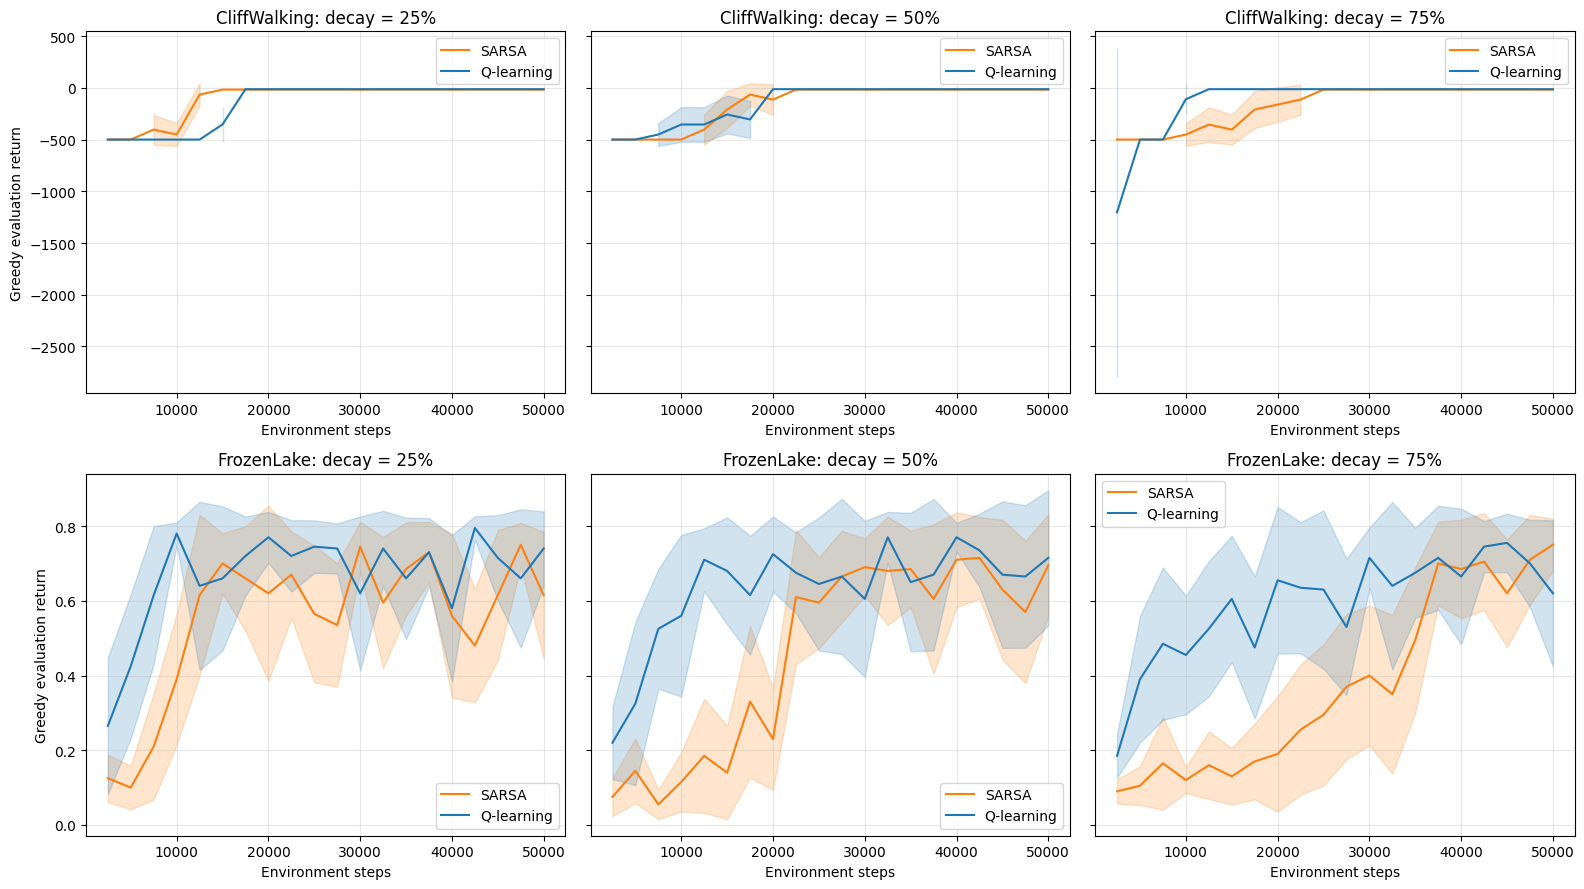

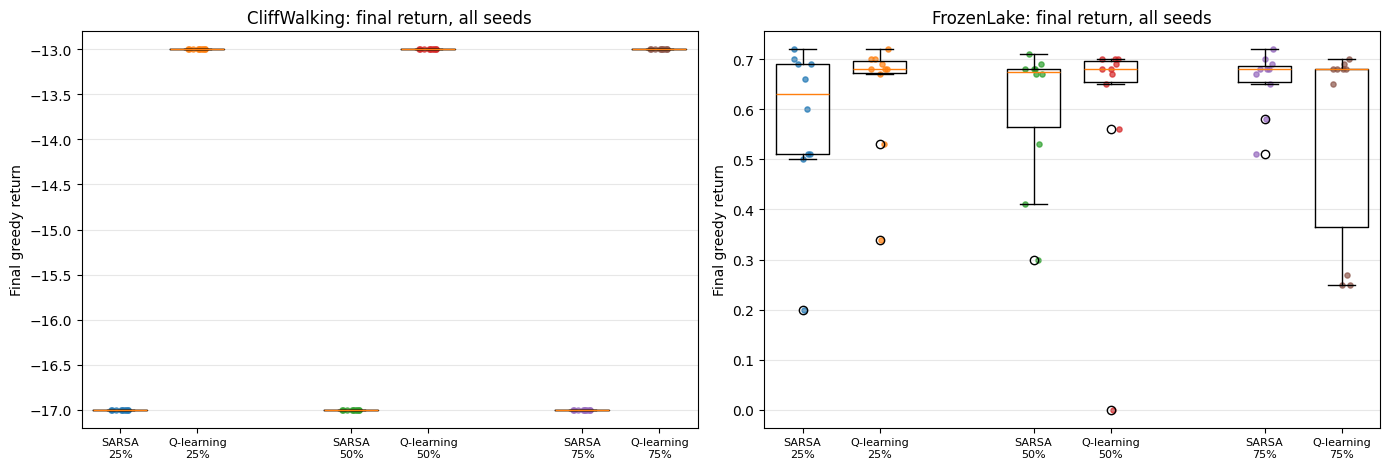

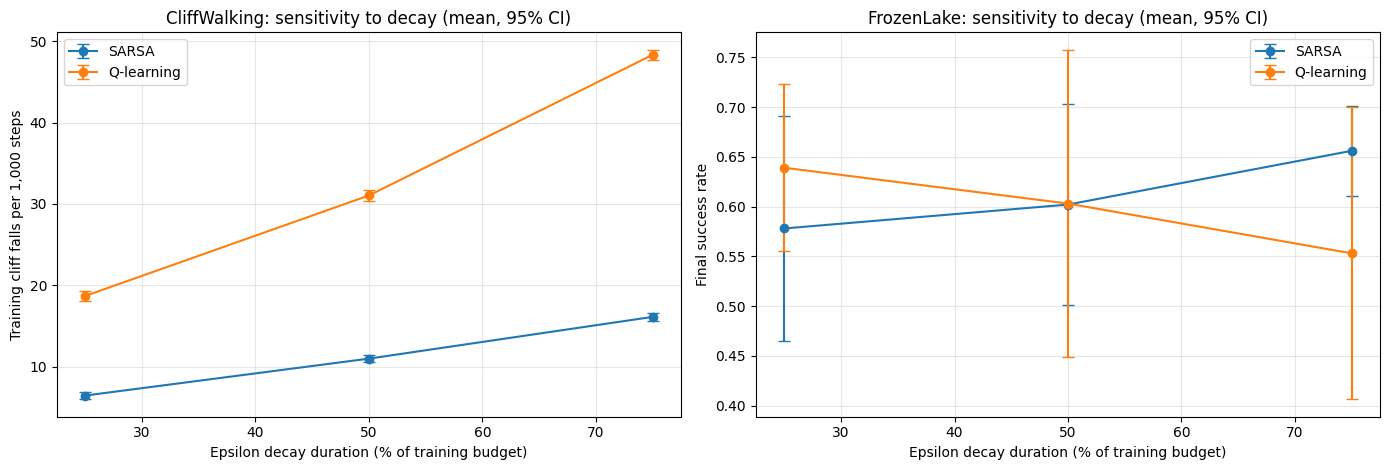

In [12]:
# CELL 12 - Figures: learning curves, final distributions, sensitivity (both environments)
import matplotlib.pyplot as plt
# Figure 1: learning curves (mean with 95% CI). Rows = environment, columns = decay level
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey='row')
for row_i, env_name in enumerate(ENV_NAMES):
    for ax, decay in zip(axes[row_i], DECAY_FRACTIONS):
        sub = learning_df[(learning_df['environment'] == env_name) &
                          np.isclose(learning_df['decay_fraction'], decay)]
        for algorithm, color in zip(ALGORITHMS, ['tab:orange', 'tab:blue']):
            a = sub[sub['algorithm'] == algorithm]
            steps, means, lows, highs = [], [], [], []
            for step, g in a.groupby('steps'):
                m, lo, hi = mean_ci(g['mean_return'].to_numpy())
                steps.append(step); means.append(m); lows.append(lo); highs.append(hi)
            ax.plot(steps, means, color=color, label=algorithm)
            ax.fill_between(steps, lows, highs, color=color, alpha=0.2)
        ax.set_title(f'{env_name}: decay = {int(decay*100)}%')
        ax.set_xlabel('Environment steps'); ax.grid(alpha=0.3); ax.legend()
    axes[row_i][0].set_ylabel('Greedy evaluation return')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'figure1_learning_curves.png', dpi=200); plt.show()

# Figure 2: final return distributions, one point per seed
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, env_name in zip(axes, ENV_NAMES):
    positions, labels, data = [], [], []
    for i, decay in enumerate(DECAY_FRACTIONS):
        for j, algorithm in enumerate(ALGORITHMS):
            v = analysis_df[(analysis_df['environment'] == env_name) &
                            (analysis_df['algorithm'] == algorithm) &
                            np.isclose(analysis_df['decay_fraction'], decay)]['final_return'].to_numpy()
            data.append(v); positions.append(i * 3 + j); labels.append(f'{algorithm}\n{int(decay*100)}%')
    ax.boxplot(data, positions=positions, widths=0.7)
    for p, v in zip(positions, data):
        ax.scatter(np.full(len(v), p) + np.random.default_rng(0).uniform(-0.12, 0.12, len(v)), v, s=14, alpha=0.7)
    ax.set_xticks(positions); ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel('Final greedy return'); ax.set_title(f'{env_name}: final return, all seeds')
    ax.grid(alpha=0.3, axis='y')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'figure2_final_return_distribution.png', dpi=200); plt.show()

# Figure 3: sensitivity of training hazard falls (CliffWalking) and final success (FrozenLake) to decay
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (env_name, metric, ylabel) in zip(axes, [
        ('CliffWalking', 'training_hazard_falls_per_1000', 'Training cliff falls per 1,000 steps'),
        ('FrozenLake', 'final_success_rate', 'Final success rate')]):
    for algorithm in ALGORITHMS:
        means, errs = [], [[], []]
        for decay in DECAY_FRACTIONS:
            v = analysis_df[(analysis_df['environment'] == env_name) &
                            (analysis_df['algorithm'] == algorithm) &
                            np.isclose(analysis_df['decay_fraction'], decay)][metric].to_numpy()
            m, lo, hi = mean_ci(v)
            means.append(m); errs[0].append(m - lo); errs[1].append(hi - m)
        ax.errorbar(np.array(DECAY_FRACTIONS) * 100, means, yerr=errs, marker='o', capsize=4, label=algorithm)
    ax.set_xlabel('Epsilon decay duration (% of training budget)')
    ax.set_ylabel(ylabel); ax.set_title(f'{env_name}: sensitivity to decay (mean, 95% CI)')
    ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'figure3_decay_sensitivity.png', dpi=200); plt.show()

In [13]:
# CELL 13 - Learned greedy policies (one representative seed, 50% decay), both environments
def print_grid_policy(env_name, Q, title):
    print(title)
    if env_name == 'CliffWalking':
        arrows = {0: '^', 1: '>', 2: 'v', 3: '<'}            # up, right, down, left
        for r in range(4):
            row = []
            for c in range(12):
                s = r * 12 + c
                if r == 3 and 1 <= c <= 10: row.append('C')
                elif s == 36: row.append('S')
                elif s == 47: row.append('G')
                else: row.append(arrows[int(np.argmax(Q[s]))])
            print(' '.join(f'{x:>2}' for x in row))
        print('Legend: C = cliff, S = start, G = goal, arrows = greedy action\n')
    else:
        desc = ['SFFF', 'FHFH', 'FFFH', 'HFFG']             # standard 4x4 map
        arrows = {0: '<', 1: 'v', 2: '>', 3: '^'}            # left, down, right, up
        for r in range(4):
            row = []
            for c in range(4):
                ch = desc[r][c]
                row.append(ch if ch in 'SHG' else arrows[int(np.argmax(Q[r * 4 + c]))])
            print(' '.join(f'{x:>2}' for x in row))
        print('Legend: H = hole, S = start, G = goal, arrows = greedy action\n')

for env_name in ENV_NAMES:
    for algorithm in ALGORITHMS:
        Q, _, _ = train_one(env_name, algorithm, alpha_choice[(env_name, algorithm, 0.5)], 0.5,
                            FINAL_SEEDS[0], TRAIN_STEPS)
        print_grid_policy(env_name, Q, f'{env_name} | {algorithm} (decay 50%, seed {FINAL_SEEDS[0]}):')

CliffWalking | SARSA (decay 50%, seed 42):
 >  >  >  >  >  >  >  >  >  >  >  v
 ^  ^  ^  >  ^  ^  >  ^  ^  ^  >  v
 ^  ^  ^  ^  ^  ^  >  >  ^  ^  >  v
 S  C  C  C  C  C  C  C  C  C  C  G
Legend: C = cliff, S = start, G = goal, arrows = greedy action

CliffWalking | Q-learning (decay 50%, seed 42):
 v  ^  >  >  ^  v  >  >  ^  v  v  v
 <  >  >  v  >  >  v  >  >  v  >  v
 >  >  >  >  >  >  >  >  >  >  >  v
 S  C  C  C  C  C  C  C  C  C  C  G
Legend: C = cliff, S = start, G = goal, arrows = greedy action

FrozenLake | SARSA (decay 50%, seed 42):
 S  ^  v  ^
 <  H  >  H
 ^  v  <  H
 H  >  v  G
Legend: H = hole, S = start, G = goal, arrows = greedy action

FrozenLake | Q-learning (decay 50%, seed 42):
 S  ^  ^  ^
 <  H  <  H
 ^  v  <  H
 H  >  v  G
Legend: H = hole, S = start, G = goal, arrows = greedy action



In [14]:
# CELL 14 - Save a manifest so anyone can reproduce and audit the run
manifest = {'environments': ENVS, 'quick_test': QUICK_TEST, 'gamma': GAMMA,
            'final_training_steps': TRAIN_STEPS, 'tuning_steps': TUNE_STEPS,
            'algorithms': ALGORITHMS, 'decay_fractions': DECAY_FRACTIONS,
            'alpha_candidates': ALPHA_CANDIDATES, 'tuning_seeds': TUNING_SEEDS,
            'final_seeds': FINAL_SEEDS, 'evaluation_interval': EVAL_INTERVAL,
            'checkpoint_eval_episodes': CHECKPOINT_EPISODES, 'final_eval_episodes': FINAL_EVAL_EPISODES,
            'evaluation_max_steps': EVAL_MAX_STEPS, 'epsilon_start': EPS_START, 'epsilon_min': EPS_MIN,
            'software_versions': versions}
with open(OUTPUT_DIR / 'experiment_manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2, default=str)
print('Saved. Files in', OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.iterdir()):
    print(' ', p.name)

Saved. Files in /content/drive/MyDrive/RL_SARSA_QLearning_Project/outputs
  Q_CliffWalking_Qlearning_d0.25_s42.npy
  Q_CliffWalking_Qlearning_d0.25_s43.npy
  Q_CliffWalking_Qlearning_d0.25_s44.npy
  Q_CliffWalking_Qlearning_d0.25_s45.npy
  Q_CliffWalking_Qlearning_d0.25_s46.npy
  Q_CliffWalking_Qlearning_d0.25_s47.npy
  Q_CliffWalking_Qlearning_d0.25_s48.npy
  Q_CliffWalking_Qlearning_d0.25_s49.npy
  Q_CliffWalking_Qlearning_d0.25_s50.npy
  Q_CliffWalking_Qlearning_d0.25_s51.npy
  Q_CliffWalking_Qlearning_d0.5_s42.npy
  Q_CliffWalking_Qlearning_d0.5_s43.npy
  Q_CliffWalking_Qlearning_d0.5_s44.npy
  Q_CliffWalking_Qlearning_d0.5_s45.npy
  Q_CliffWalking_Qlearning_d0.5_s46.npy
  Q_CliffWalking_Qlearning_d0.5_s47.npy
  Q_CliffWalking_Qlearning_d0.5_s48.npy
  Q_CliffWalking_Qlearning_d0.5_s49.npy
  Q_CliffWalking_Qlearning_d0.5_s50.npy
  Q_CliffWalking_Qlearning_d0.5_s51.npy
  Q_CliffWalking_Qlearning_d0.75_s42.npy
  Q_CliffWalking_Qlearning_d0.75_s43.npy
  Q_CliffWalking_Qlearning_d0.75_s